# 01 · Data ingestion: four free data streams

<a href="https://colab.research.google.com/github/FarhanRajputFelix/saans/blob/main/notebooks/01_data_ingestion.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

SAANS fuses four open sources into one hourly picture of each city:

| Source | What it tells us | Downloader |
|---|---|---|
| Open-Meteo (ERA5 reanalysis) | Hourly wind, humidity, temperature and boundary layer height | `saans/ingest/weather.py` |
| OpenAQ v3 | Hourly PM2.5 from reference monitors and low-cost sensors | `saans/ingest/openaq.py` |
| NASA FIRMS | Every satellite-detected fire over the Punjab-Haryana burning belt and Sindh | `saans/ingest/firms.py` |
| GDELT news index | Smog headlines that the LLM turns into an event calendar (notebook 05) | `saans/ingest/news.py` |

The downloaders are plain Python modules, run once from the command line (`python -m saans.ingest.weather` etc.). They save every API response untouched in `data/raw/`, then parse it into tidy tables in `data/interim/`. For each source this notebook shows **how it was downloaded** (the request, the download code exactly as it ran, and one raw response as it arrived), then **what arrived**, before any cleaning. A one-page summary of all of this is in [`docs/DATA_PIPELINE.md`](../docs/DATA_PIPELINE.md).

**Study period: 1 Jan 2020 to 31 Jan 2026.** The proposal covers 2020 to 2025 and tests on the 2024 and 2025 smog seasons; a season runs October to January, so the 2025 season ends on 31 January 2026. Data after that is used by the live forecast (notebook 07).

**Setup.** Runs the same way locally and in Google Colab. In Colab it clones the repo (which includes the cleaned data) and reads API keys from Colab's *Secrets* panel (key icon on the left).

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules:
    if not os.path.exists("/content/saans"):
        subprocess.run(["git", "clone", "-q", "https://github.com/FarhanRajputFelix/saans.git", "/content/saans"], check=True)
    os.chdir("/content/saans")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm", "shap", "python-dotenv"], check=True)
    from google.colab import userdata
    for k in ["OPENAQ_API_KEY", "FIRMS_MAP_KEY", "GEMINI_API_KEY", "GROQ_API_KEY"]:
        try:
            os.environ[k] = userdata.get(k)
        except Exception:
            pass
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # work from the repo root so `saans` and `data/` resolve
sys.path.insert(0, os.getcwd())

In [2]:
import inspect
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from saans.config import CITIES, INTERIM, RAW, REPORTS, LOCAL_TZ, START_DATE, END_DATE
from saans import viz
from saans.ingest import firms, news, openaq, weather

viz.use_style()
(REPORTS / "figures").mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
print(f"Study period: {START_DATE} to {END_DATE}")

def show_code(fn):
    """Display a downloader function's source code, exactly as it ran."""
    display(Markdown(f"```python\n{inspect.getsource(fn)}```"))

def show_raw(rel_path, pick=lambda x: x, chars=1800):
    """Show a raw API response as it was saved in data/raw (not committed to GitHub: too large)."""
    p = RAW / rel_path
    if not p.exists():
        print(f"{p.relative_to(RAW.parent.parent)} is not in the repository (raw files are large); run the downloader to recreate it.")
        return
    if p.suffix == ".csv":
        print("".join(p.open(encoding="utf-8").readlines()[:6]))
    else:
        display(Markdown(f"```json\n{json.dumps(pick(json.loads(p.read_text(encoding='utf-8'))), indent=1, ensure_ascii=False)[:chars]}\n```"))

# Set to True to re-run every download (needs API keys; about 2 hours, mostly NASA FIRMS)
REDOWNLOAD = False
if REDOWNLOAD:
    weather.main(); openaq.coverage(); openaq.hours(); openaq.pm10(); firms.main([]); news.main()

Study period: 2020-01-01 to 2026-01-31


## 1. Weather: Open-Meteo historical API (ERA5)

13 hourly variables for each city, 1 Jan 2020 to 31 Jan 2026, stored in UTC. ERA5 is a weather model re-run over the past and corrected with observations, on a ~25 km grid, so it has (almost) no gaps.

**How it was downloaded.** Endpoint `https://archive-api.open-meteo.com/v1/archive` (no key needed). One request per city per calendar year, asking for the 13 variables in UTC (`timezone=GMT`) and wind in m/s: 5 cities x 7 years = **35 requests**, 5 seconds apart to stay under the free limit of 600 calls per minute. Each response is saved untouched as `data/raw/open_meteo/<city>_<year>.json`; a re-run skips files already saved. The download function, exactly as it ran (`saans/ingest/weather.py`):

In [3]:
show_code(weather.download)

```python
def download(city: City, year: int, start: date, end: date) -> Path:
    path = RAW_DIR / f"{city.slug}_{year}.json"
    if path.exists():
        return path
    params = {
        "latitude": city.lat,
        "longitude": city.lon,
        "start_date": start.isoformat(),
        "end_date": end.isoformat(),
        "hourly": ",".join(VARIABLES),
        "timezone": "GMT",          # store UTC; convert to Pakistan time only when needed
        "wind_speed_unit": "ms",    # m/s instead of the default km/h
    }
    for attempt in range(5):
        r = requests.get(URL, params=params, timeout=120)
        if r.status_code == 429:  # rate limited: wait a minute and retry
            print("    rate limited, waiting 60 s")
            time.sleep(60)
            continue
        r.raise_for_status()
        break
    else:
        raise RuntimeError(f"Open-Meteo kept rate-limiting {city.slug} {year}")
    path.write_text(r.text, encoding="utf-8")
    time.sleep(PAUSE_S)
    return path
```

One raw response as it arrived (Lahore, 2024; the first 3 hours of each variable shown):

In [4]:
show_raw("open_meteo/lahore_2024.json",
         lambda d: {**{k: d[k] for k in ["latitude", "longitude", "elevation", "timezone"]},
                    "hourly": {k: v[:3] for k, v in d["hourly"].items()}})

```json
{
 "latitude": 31.528997,
 "longitude": 74.38995,
 "elevation": 222.0,
 "timezone": "GMT",
 "hourly": {
  "time": [
   "2024-01-01T00:00",
   "2024-01-01T01:00",
   "2024-01-01T02:00"
  ],
  "temperature_2m": [
   6.3,
   7.0,
   7.2
  ],
  "relative_humidity_2m": [
   98,
   99,
   98
  ],
  "dew_point_2m": [
   6.1,
   6.8,
   6.9
  ],
  "precipitation": [
   0.0,
   0.0,
   0.0
  ],
  "surface_pressure": [
   992.1,
   992.7,
   993.2
  ],
  "cloud_cover": [
   100,
   100,
   100
  ],
  "wind_speed_10m": [
   0.78,
   1.0,
   0.89
  ],
  "wind_direction_10m": [
   320,
   354,
   27
  ],
  "wind_gusts_10m": [
   2.5,
   2.8,
   2.7
  ],
  "wind_speed_100m": [
   2.42,
   2.06,
   0.92
  ],
  "wind_direction_100m": [
   308,
   331,
   13
  ],
  "shortwave_radiation": [
   0.0,
   0.0,
   0.0
  ],
  "boundary_layer_height": [
   null,
   null,
   null
  ]
 }
}
```

**What arrived:**

In [5]:
wx = pd.read_parquet(INTERIM / "weather_hourly.parquet")
print(f"{len(wx):,} hourly rows x {wx.shape[1] - 2} variables")
wx.head()

266,760 hourly rows x 13 variables


,city,time_utc,temperature_2m,relative_humidity_2m,dew_point_2m,precipitation,surface_pressure,cloud_cover,wind_speed_10m,wind_direction_10m,wind_gusts_10m,wind_speed_100m,wind_direction_100m,shortwave_radiation,boundary_layer_height
0,faisalabad,2020-01-01 00:00:00+00:00,2.4,97,2.0,0.0,998.5,95,1.82,9,2.9,4.62,18,0.0,35.0
1,faisalabad,2020-01-01 01:00:00+00:00,2.2,97,1.8,0.0,998.5,95,1.66,25,3.0,4.65,28,0.0,30.0
2,faisalabad,2020-01-01 02:00:00+00:00,1.5,98,1.2,0.0,998.7,95,2.10,25,2.9,4.16,35,0.0,20.0
3,faisalabad,2020-01-01 03:00:00+00:00,3.3,95,2.6,0.0,999.6,96,1.89,32,2.9,3.89,42,30.0,30.0
4,faisalabad,2020-01-01 04:00:00+00:00,5.7,89,4.0,0.0,1000.4,95,1.63,47,4.0,3.52,55,148.0,50.0


In [6]:
summary = wx.groupby("city").agg(rows=("time_utc", "size"), first=("time_utc", "min"), last=("time_utc", "max"))
summary["missing_cells"] = wx.drop(columns="time_utc").groupby("city").apply(lambda g: int(g.isna().sum().sum()))
summary

,rows,first,last,missing_cells
city,,,,
faisalabad,53352,2020-01-01 00:00:00+00:00,2026-01-31 23:00:00+00:00,4368
islamabad,53352,2020-01-01 00:00:00+00:00,2026-01-31 23:00:00+00:00,4368
karachi,53352,2020-01-01 00:00:00+00:00,2026-01-31 23:00:00+00:00,4368
lahore,53352,2020-01-01 00:00:00+00:00,2026-01-31 23:00:00+00:00,4368
multan,53352,2020-01-01 00:00:00+00:00,2026-01-31 23:00:00+00:00,4368


Every city has every expected hour, but each shows exactly **4,368 missing cells** (182 days x 24 hours), too round to be random:

In [7]:
na = wx[wx.boundary_layer_height.isna()]
print("Variable(s) with gaps:", [c for c in wx.columns if wx[c].isna().any()])
print("Gap:", na.time_utc.min(), "to", na.time_utc.max(), "| identical in all cities:", na.groupby("city").size().nunique() == 1)

Variable(s) with gaps: ['boundary_layer_height']
Gap: 2024-01-01 00:00:00+00:00 to 2024-06-30 23:00:00+00:00 | identical in all cities: True


Boundary layer height is missing from Jan to Jun 2024. The same hole appears in every model Open-Meteo serves (checked: `best_match`, `era5`, `era5_seamless`, `ecmwf_ifs`), so it is a gap in the provider's archive. It is logged as finding **W1** and fixed in notebook 02 by imputation.

Why boundary layer height matters: it is the height of the "lid" that traps pollution near the ground. On winter nights it collapses.

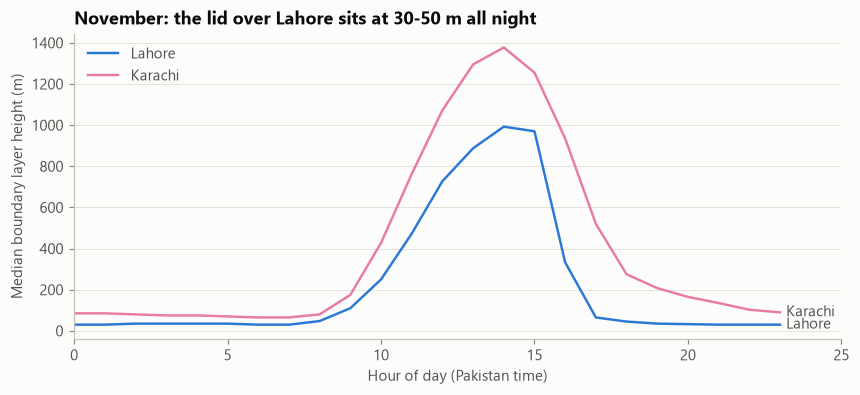

In [8]:
wx["time_pkt"] = wx.time_utc.dt.tz_convert(LOCAL_TZ)
nov = wx[wx.time_pkt.dt.month == 11]
fig, ax = plt.subplots(figsize=(9, 3.6))
for city in ["lahore", "karachi"]:
    s = nov[nov.city == city].groupby(nov.time_pkt.dt.hour).boundary_layer_height.median()
    ax.plot(s.index, s.values, color=viz.CITY_COLORS[city], label=CITIES[city].name)
    ax.annotate(CITIES[city].name, (23, s.values[-1]), xytext=(4, 0), textcoords="offset points",
                color=viz.INK_2, va="center")
ax.set(title="November: the lid over Lahore sits at 30-50 m all night",
       xlabel="Hour of day (Pakistan time)", ylabel="Median boundary layer height (m)", xlim=(0, 25))
ax.legend(loc="upper left")
fig.savefig(REPORTS / "figures/blh_diurnal_november.png", bbox_inches="tight")
plt.show()

## 2. Air quality: OpenAQ v3

**How it was downloaded**, in two stages, with a free key sent as the `X-API-Key` header:

1. **Find the sensors.** `GET https://api.openaq.org/v3/locations?coordinates=<lat>,<lon>&radius=25000` for each city (25 km is the API maximum) lists every monitoring location and its sensors, with the first and last reading. Saved as `data/raw/openaq/locations_<city>.json` and summarised in `data/interim/openaq_sensors.csv`.
2. **Download each sensor's hourly values.** `GET /v3/sensors/<id>/hours?datetime_from=...&datetime_to=...`, **one month per request**. A month is at most 744 hours, so it fits on one page of 1,000. Asking for a whole year needed deep paging, which slowed down (page 5 took 12 s) and then timed out (HTTP 408).

The free key allows 60 requests a minute, so four workers ran in parallel, paced on OpenAQ's rate-limit headers; timeouts, server errors and dropped connections were retried. About 1,300 requests in total. The request function and the per-sensor download, exactly as they ran (`saans/ingest/openaq.py`):

In [9]:
show_code(openaq.get)
show_code(openaq.download_sensor)

```python
def get(path: str, **params) -> dict:
    """GET with the key, pacing on OpenAQ's rate-limit headers (free tier: 60 a minute)."""
    if not OPENAQ_API_KEY:
        raise SystemExit("OPENAQ_API_KEY is empty: paste your key into .env")
    for attempt in range(8):
        try:
            r = session.get(f"{API}{path}", params=params, headers={"X-API-Key": OPENAQ_API_KEY}, timeout=120)
        except (requests.ConnectionError, requests.Timeout) as e:  # a dropped connection is retried, not fatal
            print(f"    network error ({type(e).__name__}), retrying in 30 s")
            time.sleep(30)
            continue
        reset = int(r.headers.get("x-ratelimit-reset", 60)) + 1
        if r.status_code in RETRY_CODES:
            wait = reset if r.status_code == 429 else 15 * (attempt + 1)
            print(f"    HTTP {r.status_code}, waiting {wait} s")
            time.sleep(wait)
            continue
        r.raise_for_status()
        if int(r.headers.get("x-ratelimit-remaining", 10)) < 2:
            time.sleep(reset)  # minute budget used up: wait for the window to reset
        return r.json()
    raise RuntimeError(f"OpenAQ kept failing on {path}")
```

```python
def download_sensor(sensor_id: int, first_utc: pd.Timestamp, last_utc: pd.Timestamp) -> Path:
    """Fetch one month per request. A month (<= 744 hours) fits on one page; deep paging is slow
    (page 5 of a year takes ~12 s against ~3.4 s for a month) and over six years it times out."""
    path = HOURS_DIR / f"sensor_{sensor_id}.json"
    if path.exists():
        return path
    start = max(pd.Timestamp(START_DATE, tz="UTC"), first_utc.floor("D"))
    end = min(pd.Timestamp(f"{END_DATE} 23:59:59", tz="UTC"), last_utc)
    results = []
    for m_from in pd.date_range(start.replace(day=1), end, freq="MS"):
        m_to = min(end, m_from + pd.offsets.MonthEnd(1) + pd.Timedelta(hours=23, minutes=59, seconds=59))
        payload = get(f"/sensors/{sensor_id}/hours", limit=PAGE,
                      datetime_from=max(m_from, start).strftime("%Y-%m-%dT%H:%M:%SZ"),
                      datetime_to=m_to.strftime("%Y-%m-%dT%H:%M:%SZ"))
        results += payload["results"]
    path.write_text(json.dumps(results), encoding="utf-8")
    return path
```

Raw responses as they arrived: one location from the Lahore search (the US Embassy monitor), and its first hourly record:

In [10]:
show_raw("openaq/locations_lahore.json",
         lambda d: [{k: loc.get(k) for k in ["id", "name", "provider", "isMonitor", "coordinates", "datetimeFirst", "datetimeLast"]}
                    | {"sensors": [s["name"] for s in loc["sensors"]]} for loc in d["results"] if loc.get("isMonitor")][:1])
show_raw("openaq/hours/sensor_25135.json", lambda d: d[:1], chars=1400)

```json
[
 {
  "id": 8664,
  "name": "US Diplomatic Post: Lahore",
  "provider": {
   "id": 265,
   "name": "StateAir Lahore"
  },
  "isMonitor": true,
  "coordinates": {
   "latitude": 31.560078,
   "longitude": 74.33589
  },
  "datetimeFirst": {
   "utc": "2019-05-22T22:00:00Z",
   "local": "2019-05-23T03:00:00+05:00"
  },
  "datetimeLast": {
   "utc": "2025-03-04T12:00:00Z",
   "local": "2025-03-04T17:00:00+05:00"
  },
  "sensors": [
   "pm25 µg/m³"
  ]
 }
]
```

```json
[
 {
  "value": 180.0,
  "flagInfo": {
   "hasFlags": false
  },
  "parameter": {
   "id": 2,
   "name": "pm25",
   "units": "µg/m³",
   "displayName": null
  },
  "period": {
   "label": "1hour",
   "interval": "01:00:00",
   "datetimeFrom": {
    "utc": "2020-01-01T00:00:00Z",
    "local": "2020-01-01T05:00:00+05:00"
   },
   "datetimeTo": {
    "utc": "2020-01-01T01:00:00Z",
    "local": "2020-01-01T06:00:00+05:00"
   }
  },
  "coordinates": null,
  "summary": {
   "min": 179.5,
   "q02": 179.5,
   "q25": 179.5,
   "median": 179.5,
   "q75": 179.5,
   "q98": 179.5,
   "max": 179.5,
   "avg": 179.5,
   "sd": null
  },
  "coverage": {
   "expectedCount": 1,
   "expectedInterval": "01:00:00",
   "observedCount": 1,
   "observedInterval": "01:00:00",
   "percentComplete": 100.0,
   "percentCoverage": 100.0,
   "datetimeFrom": {
    "utc": "2020-01-01T00:00:00Z",
    "local": "2020-01-01T05:00:00+05:00"
   },
   "datetimeTo": {
    "utc": "2020-01-01T01:00:00Z",
    "local": "2020-01-01T06:00:00+05:00"
   }
  }
 }
]
```

**What arrived.** The first question was coverage: how many PM2.5 sensors exist within 25 km of each city, and over which years? This was the project's first risk check.

In [11]:
sensors = pd.read_csv(INTERIM / "openaq_sensors.csv", parse_dates=["first_utc", "last_utc"])
pm = sensors[(sensors.parameter == "pm25") & (sensors.days_in_period > 0)].copy()
pm["kind"] = pm.is_monitor.map({True: "reference monitor", False: "low-cost sensor"})
pm.groupby(["city", "kind"]).agg(sensors=("sensor_id", "size"), providers=("provider", lambda s: ", ".join(sorted(set(s)))),
                                 first=("first_utc", "min"), last=("last_utc", "max"))

sensors                       providers                     first                      last
city       kind                                                                                                          
faisalabad low-cost sensor         36           AirGradient, Hawanama 2025-06-23 06:00:00+00:00 2026-10-24 07:00:00+00:00
islamabad  low-cost sensor         34           AirGradient, Hawanama 2025-05-06 07:00:00+00:00 2026-10-24 07:00:00+00:00
           reference monitor        2      AirNow, StateAir Islamabad 2019-05-22 22:00:00+00:00 2026-02-16 13:00:00+00:00
karachi    low-cost sensor         37  AirGradient, Clarity, Hawanama 2023-11-28 16:58:32+00:00 2026-10-24 07:00:00+00:00
           reference monitor        1                          AirNow 2019-05-22 22:00:00+00:00 2025-03-04 12:00:00+00:00
lahore     low-cost sensor         73  AirGradient, Clarity, Hawanama 2023-11-28 16:58:05+00:00 2026-10-24 07:00:00+00:00
           reference monitor        1                 StateAir Lahore 2019-05-22 22:00:00+00:00 2025-03-04 12:00:00+00:00
multan     low-cost sensor         16           AirGradient, Hawanama 2025-06-16 06:00:00+00:00 2026-10-24 07:00:00+00:00

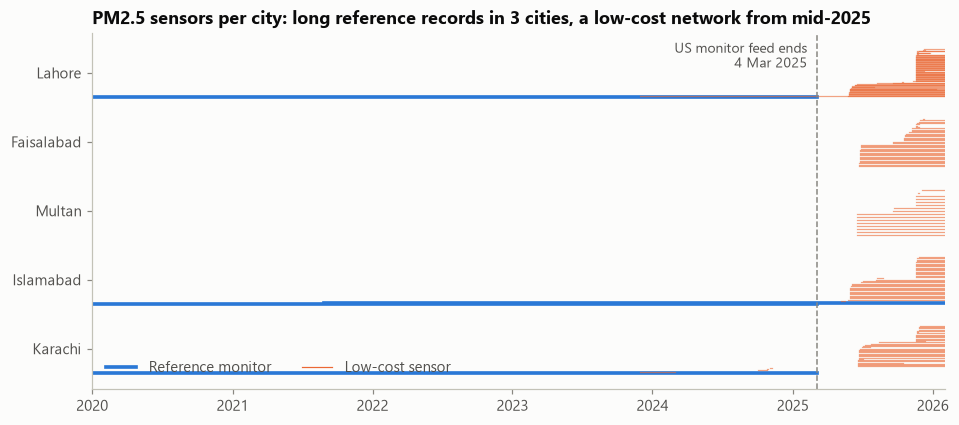

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.2))
order = ["karachi", "islamabad", "multan", "faisalabad", "lahore"]
for i, city in enumerate(order):
    g = pm[pm.city == city].sort_values("first_utc")
    for j, s in enumerate(g.itertuples()):
        y = i + (j / max(len(g), 1)) * 0.7 - 0.35
        ref = s.is_monitor
        ax.plot([s.first_utc, min(s.last_utc, pd.Timestamp("2026-01-31", tz="UTC"))], [y, y],
                color=viz.SERIES[0] if ref else viz.SERIES[1], lw=2.4 if ref else 0.8, alpha=1 if ref else 0.6)
ax.set_yticks(range(len(order)), [CITIES[c].name for c in order])
ax.axvline(pd.Timestamp("2025-03-04", tz="UTC"), color=viz.MUTED, ls="--", lw=1)
ax.annotate("US monitor feed ends\n4 Mar 2025", (pd.Timestamp("2025-03-04", tz="UTC"), 4.45), xytext=(-6, 0),
            textcoords="offset points", ha="right", va="top", color=viz.INK_2, fontsize=9)
ax.plot([], [], color=viz.SERIES[0], lw=2.4, label="Reference monitor")
ax.plot([], [], color=viz.SERIES[1], lw=0.8, label="Low-cost sensor")
ax.set(title="PM2.5 sensors per city: long reference records in 3 cities, a low-cost network from mid-2025",
       xlim=(pd.Timestamp("2020-01-01", tz="UTC"), pd.Timestamp("2026-02-01", tz="UTC")))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", ncol=2)
fig.savefig(REPORTS / "figures/sensor_coverage.png", bbox_inches="tight")
plt.show()

**Where the sensors are.** The proposal flagged uneven coverage as a risk and promised a coverage map. Each panel is a 25 km circle around a city centre:

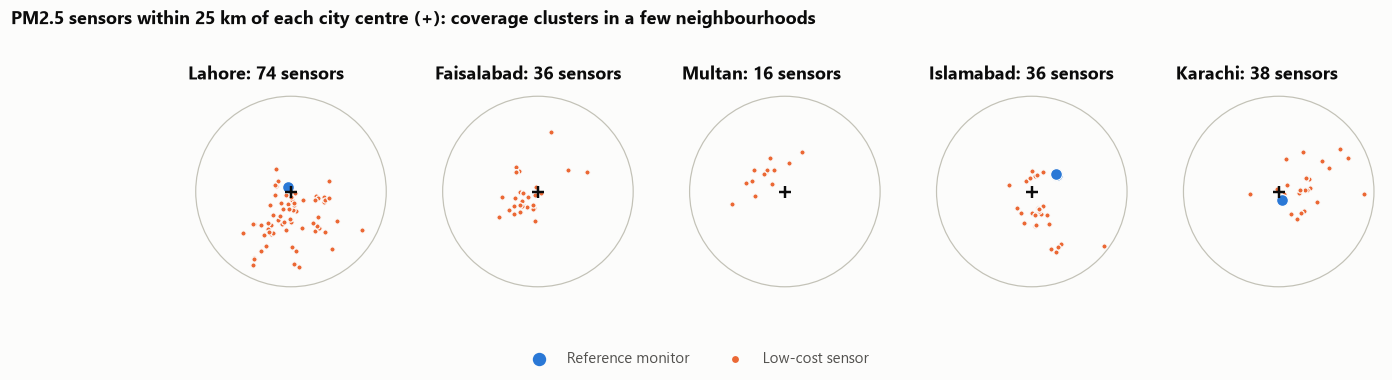

In [13]:
from matplotlib.patches import Circle
fig, axes = plt.subplots(1, 5, figsize=(14, 3.4))
for ax, city in zip(axes, ["lahore", "faisalabad", "multan", "islamabad", "karachi"]):
    c = CITIES[city]
    g = pm[pm.city == city]
    km_lat, km_lon = 1 / 111, 1 / (111 * np.cos(np.radians(c.lat)))
    ax.add_patch(Circle((0, 0), 25, fill=False, color=viz.AXIS, lw=0.8))
    for ref, color, size in [(False, viz.SERIES[1], 12), (True, viz.SERIES[0], 60)]:
        k = g[g.is_monitor == ref]
        ax.scatter((k.lon - c.lon) / km_lon, (k.lat - c.lat) / km_lat, s=size, color=color, edgecolor=viz.SURFACE, linewidth=0.8, zorder=3)
    ax.scatter(0, 0, marker="+", s=60, color=viz.INK, zorder=4)
    ax.set(title=f"{c.name}: {len(g)} sensors", xlim=(-27, 27), ylim=(-27, 27), xticks=[], yticks=[])
    ax.set_aspect("equal"); ax.grid(visible=False)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].scatter([], [], s=60, color=viz.SERIES[0], label="Reference monitor")
axes[0].scatter([], [], s=12, color=viz.SERIES[1], label="Low-cost sensor")
fig.legend(loc="lower center", ncol=2, frameon=False)
fig.suptitle("PM2.5 sensors within 25 km of each city centre (+): coverage clusters in a few neighbourhoods", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.savefig(REPORTS / "figures/sensor_map.png", bbox_inches="tight")
plt.show()

What the coverage check shows, and how the design responds:

* **Lahore, Islamabad and Karachi** have reference monitors at the US diplomatic posts from 2019. That feed **stopped on 4 March 2025**. Lahore also has a Clarity monitor from Nov 2023 and Islamabad a second AirNow feed until Feb 2026.
* **Faisalabad and Multan** have no history before mid-2025: only AirGradient low-cost sensors, installed in June 2025.
* So the model trains on Lahore, Islamabad and Karachi (2020 to Sep 2024), is tested on the 2024 season, and is then tested on **Faisalabad and Multan in the 2025 season, cities it has never seen**. That is a stricter test than the proposal planned.

Next, the hourly values themselves:

**PM10 and NO2.** The proposal also planned PM10 and NO2. Within 25 km of the five cities, OpenAQ lists only **5 PM10 sensors** and **no NO2 sensor at all**:

In [14]:
print(sensors[sensors.days_in_period > 0].groupby("parameter").sensor_id.nunique().to_dict())
pm10 = pd.read_parquet(INTERIM / "openaq_pm10_hourly.parquet")
print(f"{len(pm10):,} hourly PM10 records from {pm10.sensor_id.nunique()} sensors:", pm10.groupby("city").size().to_dict())

{'pm10': 5, 'pm25': 200}
5,904 hourly PM10 records from 5 sensors: {'karachi': 2426, 'lahore': 3478}


In [15]:
aq = pd.read_parquet(INTERIM / "openaq_hourly.parquet")
print(f"{len(aq):,} hourly PM2.5 records from {aq.sensor_id.nunique()} sensors")
aq.groupby("city").agg(records=("value", "size"), sensors=("sensor_id", "nunique"),
                       first=("time_utc", "min"), last=("time_utc", "max"), median_ug_m3=("value", "median"))

587,969 hourly PM2.5 records from 200 sensors


,records,sensors,first,last,median_ug_m3
city,,,,,
faisalabad,94774,36,2025-06-23 05:00:00+00:00,2026-01-31 22:00:00+00:00,133.0
islamabad,153135,36,2020-01-01 00:00:00+00:00,2026-01-31 22:00:00+00:00,47.9
karachi,118133,38,2020-01-01 00:00:00+00:00,2026-01-31 22:00:00+00:00,35.8
lahore,188589,74,2020-01-01 00:00:00+00:00,2026-01-31 22:00:00+00:00,107.0
multan,33338,16,2025-06-16 05:00:00+00:00,2026-01-31 22:00:00+00:00,99.0


**From when to when, per city and network** (inside the study period). Reference monitors give Lahore, Islamabad and Karachi a continuous record from 2020 until the US feed stopped on 4 March 2025; the low-cost networks start in 2024-2025 and are still reporting today.

In [16]:
span = (aq.merge(sensors.drop_duplicates("sensor_id")[["sensor_id", "provider"]], on="sensor_id")
        .groupby(["city", "provider"]).agg(sensors=("sensor_id", "nunique"), hours=("value", "size"),
                                           first=("time_utc", "min"), last=("time_utc", "max")))
span["first"], span["last"] = span["first"].dt.strftime("%d %b %Y"), span["last"].dt.strftime("%d %b %Y")
span

sensors  hours        first         last
city       provider                                                    
faisalabad AirGradient              29  94427  23 Jun 2025  31 Jan 2026
           Hawanama                  7    347  18 Nov 2025  31 Jan 2026
islamabad  AirGradient              18  72807  06 May 2025  31 Jan 2026
           AirNow                    1  28544  26 Aug 2021  31 Jan 2026
           Hawanama                 16  13381  18 Nov 2025  31 Jan 2026
           StateAir Islamabad        1  38403  01 Jan 2020  04 Mar 2025
karachi    AirGradient              23  68097  02 Oct 2024  31 Jan 2026
           AirNow                    1  41761  01 Jan 2020  04 Mar 2025
           Clarity                   1   2181  28 Nov 2023  28 Feb 2024
           Hawanama                 13   6094  18 Nov 2025  31 Jan 2026
lahore     AirGradient              23  88063  24 May 2025  31 Jan 2026
           Clarity                   1  15542  28 Nov 2023  31 Jan 2026
           Hawanama                 49  43680  18 Nov 2025  31 Jan 2026
           StateAir Lahore           1  41304  01 Jan 2020  04 Mar 2025
multan     AirGradient              10  29671  16 Jun 2025  31 Jan 2026
           Hawanama                  6   3667  18 Nov 2025  31 Jan 2026

## 3. Fires: NASA FIRMS

Every fire pixel detected by two satellite instruments over the box 66-78 E, 24-34 N (Pakistani and Indian Punjab, Haryana, and Sindh down to Karachi):

* **VIIRS on Suomi-NPP**: 375 m pixels, passes at about 01:30 and 13:30 local time
* **MODIS on Terra and Aqua**: 1 km pixels, passes at about 10:30 and 13:30

**How it was downloaded.** Endpoint `https://firms.modaps.eosdis.nasa.gov/api/area/csv/<MAP_KEY>/<SOURCE>/66,24,78,34/<days>/<date>`, with NASA's standard science-quality archives `VIIRS_SNPP_SP` and `MODIS_SP`. The API returns at most 5 days per call, so each month was fetched in 5-day chunks and saved as one CSV: 73 months x 2 sources = **146 files**. To finish in time, two workers ran per source, one forward from 2020 and one backward from 2026. The key allows 5,000 transactions per 10 minutes; above that FIRMS answers "Invalid MAP_KEY", so the downloader waits and retries. (VIIRS on NOAA-20 was also tried, but it downloaded about 3x slower, an estimated 5 hours, so it was left out.) The download code, exactly as it ran (`saans/ingest/firms.py`):

In [17]:
show_code(firms.fetch_chunk)
show_code(firms.download_month)

```python
def fetch_chunk(source: str, start: date, days: int) -> str:
    area = ",".join(str(v) for v in BBOX)
    url = f"{API}/area/csv/{key()}/{source}/{area}/{days}/{start.isoformat()}"
    for attempt in range(8):
        r = requests.get(url, timeout=180)
        time.sleep(PAUSE_S)
        text = r.text
        if r.status_code == 200 and (text.startswith("latitude") or not text.strip()):
            return text  # a CSV, possibly just the header when there were no fires
        # FIRMS reports errors as plain text with HTTP 200. Over the 5,000-per-10-minutes quota it
        # answers "Invalid MAP_KEY" (observed on 2026-10-24 at 4,886/5,000), so wait for the window.
        print(f"    {source} {start}: HTTP {r.status_code} {text[:100]!r}, waiting 120 s")
        time.sleep(120)
    raise RuntimeError(f"FIRMS kept failing on {source} {start} (key valid? quota?)")
```

```python
def download_month(source: str, first: date, last: date) -> None:
    path = RAW_DIR / source / f"{first:%Y-%m}.csv"
    if path.exists():
        return
    parts, day = [], first
    while day <= last:
        days = min(5, (last - day).days + 1)
        text = fetch_chunk(source, day, days)
        if text.strip():
            parts.append(pd.read_csv(io.StringIO(text)))
        day += timedelta(days=days)
    df = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=False)
```

The first lines of one raw file as it arrived (VIIRS, November 2024). NASA stores the time as an `HHMM` integer in UTC (`acq_time` 845 means 08:45):

In [18]:
show_raw("firms/VIIRS_SNPP_SP/2024-11.csv")

latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight,type
24.07875,77.94083,347.14,0.48,0.48,2024-11-01,825,N,VIIRS,n,2,307.8,6.93,D,0
24.16243,77.89763,340.88,0.48,0.48,2024-11-01,825,N,VIIRS,n,2,303.67,4.24,D,0
24.3542,77.44711,337.72,0.45,0.47,2024-11-01,825,N,VIIRS,n,2,306.63,2.17,D,0
24.36903,77.98167,341.8,0.49,0.48,2024-11-01,825,N,VIIRS,n,2,304.88,2.47,D,0
24.36922,77.4635,342.74,0.45,0.47,2024-11-01,825,N,VIIRS,n,2,308.08,4.65,D,0



**What arrived**, with the `HHMM` time parsed into a proper UTC timestamp:

In [19]:
fires = pd.read_parquet(INTERIM / "firms_fires.parquet")
print(f"{len(fires):,} fire detections")
fires[["acq_date", "acq_time", "time_utc", "latitude", "longitude", "frp", "confidence", "source", "type"]].head()

1,185,836 fire detections


,acq_date,acq_time,time_utc,latitude,longitude,frp,confidence,source,type
0,2020-01-01,534,2020-01-01 05:34:00+00:00,33.18270,74.07740,12.30,48,MODIS_SP,0
1,2020-01-01,537,2020-01-01 05:37:00+00:00,25.26750,75.69580,6.20,57,MODIS_SP,0
2,2020-01-01,537,2020-01-01 05:37:00+00:00,25.26610,75.70610,13.40,76,MODIS_SP,0
3,2020-01-01,838,2020-01-01 08:38:00+00:00,26.94843,67.83544,5.03,n,VIIRS_SNPP_SP,0
4,2020-01-01,838,2020-01-01 08:38:00+00:00,25.10702,67.10941,3.78,n,VIIRS_SNPP_SP,0


C:\Users\Laptronics.co\AppData\Local\Temp\ipykernel_6092\2937792272.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  monthly = fires.groupby([fires.time_utc.dt.to_period("M"), "source"]).size().unstack().fillna(0)


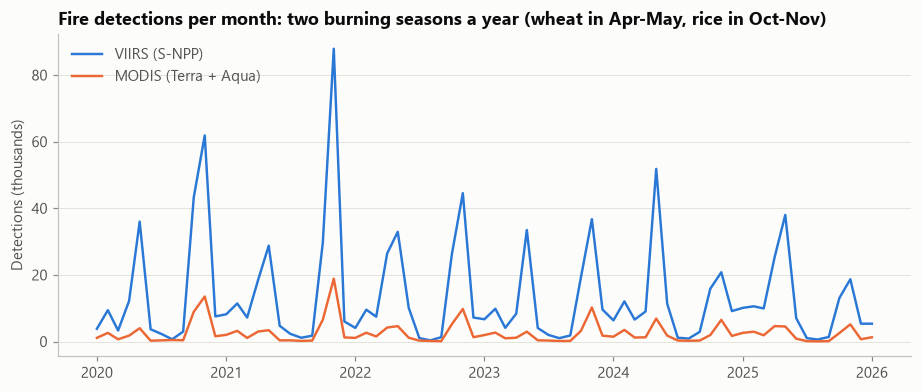

In [20]:
monthly = fires.groupby([fires.time_utc.dt.to_period("M"), "source"]).size().unstack().fillna(0)
fig, ax = plt.subplots(figsize=(10, 3.8))
names = {"VIIRS_SNPP_SP": "VIIRS (S-NPP)", "MODIS_SP": "MODIS (Terra + Aqua)"}
for k, src in enumerate(["VIIRS_SNPP_SP", "MODIS_SP"]):
    if src in monthly:
        ax.plot(monthly.index.to_timestamp(), monthly[src] / 1000, color=viz.SERIES[k], label=names[src])
ax.set(title="Fire detections per month: two burning seasons a year (wheat in Apr-May, rice in Oct-Nov)",
       ylabel="Detections (thousands)")
ax.legend(loc="upper left")
fig.savefig(REPORTS / "figures/fires_per_month.png", bbox_inches="tight")
plt.show()

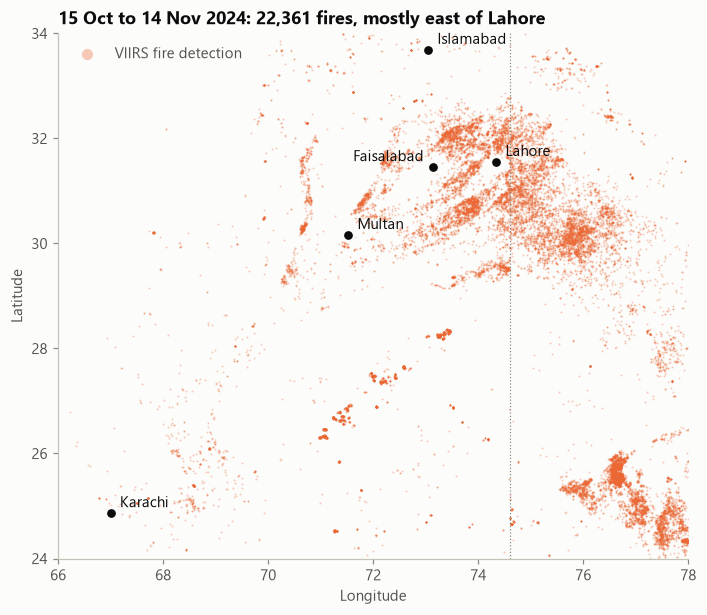

In [21]:
nov24 = fires[(fires.time_utc >= "2024-10-15") & (fires.time_utc < "2024-11-15") & (fires.source == "VIIRS_SNPP_SP")]
fig, ax = plt.subplots(figsize=(7.5, 6.2))
ax.scatter(nov24.longitude, nov24.latitude, s=1.5, color=viz.SERIES[1], alpha=0.35, linewidths=0, label="VIIRS fire detection")
for c in CITIES.values():
    ax.scatter(c.lon, c.lat, s=60, color=viz.INK, zorder=3, edgecolor=viz.SURFACE, linewidth=2)
    left = c.slug == "faisalabad"  # Faisalabad sits just west of Lahore: label it on the left so the names don't collide
    ax.annotate(c.name, (c.lon, c.lat), xytext=(-6 if left else 6, 4), textcoords="offset points", fontsize=10,
                color=viz.INK, ha="right" if left else "left")
ax.axvline(74.6, color=viz.MUTED, lw=0.8, ls=":")  # rough line of the India-Pakistan border near Lahore
ax.set(title=f"15 Oct to 14 Nov 2024: {len(nov24):,} fires, mostly east of Lahore", xlabel="Longitude", ylabel="Latitude",
       xlim=(66, 78), ylim=(24, 34))
ax.set_aspect("equal")
ax.grid(visible=False)
ax.legend(loc="upper left", markerscale=6)
fig.savefig(REPORTS / "figures/fires_map_nov2024.png", bbox_inches="tight")
plt.show()

The dotted line is a rough marker of the border east of Lahore. Most of the rice-stubble fires burn in Indian Punjab and Haryana, upwind of Lahore when the wind blows from the east-southeast, which is what the Upwind Fire Exposure Index in notebook 04 measures.

## 4. News headlines: GDELT

GDELT indexes online news worldwide. Only the headline, outlet, link and date are kept; notebook 03 turns them into structured events.

**How it was downloaded.** Endpoint `https://api.gdeltproject.org/api/v2/doc/doc` (no key), `mode=artlist`, up to 250 articles per request, with the query `(smog OR AQI) (Lahore OR Punjab OR Multan OR Faisalabad OR Islamabad OR Karachi) sourcecountry:pakistan`. Two windows per smog season (October-November and December-January): **13 requests**. GDELT allows about one request every 5 seconds and throttled hard (HTTP 429), so requests were spaced 10 seconds apart and retried after 30 seconds. The download code (`saans/ingest/news.py`):

In [22]:
show_code(news.fetch)
show_raw("gdelt/2024-10-01.json", lambda d: d["articles"][:2])

```python
def fetch(first: date, last: date) -> list[dict]:
    path = RAW_DIR / f"{first.isoformat()}.json"
    if not path.exists():
        params = {"query": QUERY, "mode": "artlist", "maxrecords": 250, "format": "json",
                  "startdatetime": f"{first:%Y%m%d}000000", "enddatetime": f"{last:%Y%m%d}235959"}
        for attempt in range(12):
            time.sleep(PAUSE_S)
            try:
                r = requests.get(API, params=params, timeout=90, headers={"User-Agent": "saans-student-project"})
            except (requests.ConnectionError, requests.Timeout):
                print("    network error, retrying in 30 s")
                time.sleep(30)
                continue
            if r.status_code == 429:
                print("    rate limited, waiting 30 s")
                time.sleep(30)
                continue
            r.raise_for_status()
            break
        else:
            raise RuntimeError(f"GDELT kept rate-limiting {first}")
        # GDELT answers an empty window with an empty body instead of {"articles": []}
        payload = r.json() if r.text.strip().startswith("{") else {"articles": []}
        path.write_text(json.dumps(payload), encoding="utf-8")
    return json.loads(path.read_text(encoding="utf-8")).get("articles", [])
```

```json
[
 {
  "url": "https://dunyanews.tv/en/Pakistan/852565-lahore-again-tops-list-of-worlds-most-polluted-city",
  "url_mobile": "https://dunyanews.tv/amp/english/852565.php",
  "title": "Lahore again tops list of world most polluted city",
  "seendate": "20241124T190000Z",
  "socialimage": "https://img.dunyanews.tv/news/2024/November/11-24-24/news_big_images/852565_53436208.jpg",
  "domain": "dunyanews.tv",
  "language": "English",
  "sourcecountry": "Pakistan"
 },
 {
  "url": "https://en.dailypakistan.com.pk/17-Nov-2024/lahores-air-quality-improves-slightly-amid-new-restrictions-in-punjab",
  "url_mobile": "",
  "title": "Lahore Air Quality improves slightly amid new restrictions in Punjab",
  "seendate": "20241117T101500Z",
  "socialimage": "https://en.dailypakistan.com.pk/wp-content/uploads/2024/10/lahore-chokes-under-another-smog-season-as-aqi-reaches-over-300-news-255647.jpg",
  "domain": "en.dailypakistan.com.pk",
  "language": "English",
  "sourcecountry": "Pakistan"
 }
]
```

**What arrived** (duplicate links and near-identical headlines removed at download):

In [23]:
news = pd.read_csv(INTERIM / "news_headlines.csv", parse_dates=["time_utc"])
print(f"{len(news):,} unique headlines from {news.domain.nunique()} outlets")
news.sample(8, random_state=1)[["time_utc", "domain", "title"]].sort_values("time_utc")

2,255 unique headlines from 42 outlets


,time_utc,domain,title
6,2020-01-02 19:00:00+00:00,dailytimes.com.pk,2019 : a year in review | Daily times
579,2021-12-15 07:45:00+00:00,samaa.tv,Lahore suffers worst smog in four years
627,2021-12-20 05:15:00+00:00,tribune.com.pk,Effective government regulations can solve s...
679,2021-12-30 06:00:00+00:00,arynews.tv,Lahore once again ranks world most polluted city
1558,2024-11-06 15:15:00+00:00,samaa.tv,Big breaking : Mask - wearing made mandatory
1928,2025-10-05 01:00:00+00:00,tribune.com.pk,Lahore tops pollution index
2045,2025-10-31 18:15:00+00:00,tribune.com.pk,Suthra Punjab worsens air quality
2080,2025-11-06 03:30:00+00:00,thenews.com.pk,Politics of optics


## 5. Raw records received

These counts are the "rows received" column of the Data Quality Report. Cleaning starts from here.

In [24]:
raw_counts = pd.DataFrame([
    ("Open-Meteo weather (hourly rows)", len(wx)),
    ("OpenAQ PM2.5 (sensor-hours)", len(aq)),
    ("OpenAQ PM10 (sensor-hours)", len(pm10)),
    ("NASA FIRMS fire detections", len(fires)),
    ("GDELT news headlines", len(news)),
], columns=["source", "raw_records"])
raw_counts.loc[len(raw_counts)] = ["Total", raw_counts.raw_records.sum()]
raw_counts.to_csv(REPORTS / "raw_record_counts.csv", index=False)
raw_counts.style.format({"raw_records": "{:,}"}).hide(axis="index")

source,raw_records
Open-Meteo weather (hourly rows),"266,760"
OpenAQ PM2.5 (sensor-hours),"587,969"
OpenAQ PM10 (sensor-hours),"5,904"
NASA FIRMS fire detections,"1,185,836"
GDELT news headlines,"2,255"
Total,"2,048,724"
